In [73]:
# import functions
# build nn class that inhirate from torch nn
    # inhirate from super in init
    # the feed forward function

In [74]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.optim import SGD

import matplotlib.pyplot as plt
import seaborn as sns

In [75]:
class FirstNN(nn.Module):
    
    def __init__(self):
        super().__init__()
        
        self.w00 = nn.Parameter(torch.tensor(1.1), requires_grad=False)
        self.b00 = nn.Parameter(torch.tensor(-0.5), requires_grad=False)

        self.w01 = nn.Parameter(torch.tensor(0.6), requires_grad=False)
        self.b01 = nn.Parameter(torch.tensor(-1.5), requires_grad=False)

        self.w02 = nn.Parameter(torch.tensor(0.5), requires_grad=False)
        self.b02 = nn.Parameter(torch.tensor(0.65), requires_grad=False)

        self.w11 = nn.Parameter(torch.tensor(1.55), requires_grad=False)
        self.w12 = nn.Parameter(torch.tensor(-0.7), requires_grad=False)
        self.w13 = nn.Parameter(torch.tensor(1.22), requires_grad=False)

        self.w20 = nn.Parameter(torch.tensor(1.6), requires_grad=False)
        
    
    def forward(self, input):
        input_to_layer_1 = input * self.w00 + self.b00
        layer_01_output = F.relu(input_to_layer_1)
        layer_01_output = layer_01_output * self.w11
        
        input_to_layer_2 = input * self.w01 + self.b01
        layer_02_output = F.relu(input_to_layer_2)
        layer_02_output = layer_02_output * self.w12
        
        input_to_layer_3 = input * self.w02 + self.b02
        layer_03_output = F.relu(input_to_layer_3)
        layer_03_output = layer_03_output * self.w13
        
        output = layer_01_output + layer_02_output + layer_03_output
        
        output = F.tanh(output)
        output = output * self.w20
        
        return output
    
    

In [76]:
first_model= FirstNN()

In [77]:
for name, param in first_model.named_parameters():
    print(name, param)

w00 Parameter containing:
tensor(1.1000)
b00 Parameter containing:
tensor(-0.5000)
w01 Parameter containing:
tensor(0.6000)
b01 Parameter containing:
tensor(-1.5000)
w02 Parameter containing:
tensor(0.5000)
b02 Parameter containing:
tensor(0.6500)
w11 Parameter containing:
tensor(1.5500)
w12 Parameter containing:
tensor(-0.7000)
w13 Parameter containing:
tensor(1.2200)
w20 Parameter containing:
tensor(1.6000)


In [78]:
true_inputs = torch.linspace(start = 0.2, end = 2.5, steps = 35)
true_inputs

tensor([0.2000, 0.2676, 0.3353, 0.4029, 0.4706, 0.5382, 0.6059, 0.6735, 0.7412,
        0.8088, 0.8765, 0.9441, 1.0118, 1.0794, 1.1471, 1.2147, 1.2824, 1.3500,
        1.4176, 1.4853, 1.5529, 1.6206, 1.6882, 1.7559, 1.8235, 1.8912, 1.9588,
        2.0265, 2.0941, 2.1618, 2.2294, 2.2971, 2.3647, 2.4324, 2.5000])

In [79]:
true_outputs = first_model(true_inputs)
true_outputs

tensor([1.1576, 1.1882, 1.2169, 1.2439, 1.2850, 1.3635, 1.4236, 1.4691, 1.5032,
        1.5287, 1.5475, 1.5615, 1.5717, 1.5793, 1.5848, 1.5889, 1.5919, 1.5941,
        1.5957, 1.5968, 1.5977, 1.5983, 1.5988, 1.5991, 1.5993, 1.5995, 1.5996,
        1.5997, 1.5998, 1.5999, 1.5999, 1.5999, 1.5999, 1.6000, 1.6000])

Text(0, 0.5, 'output')

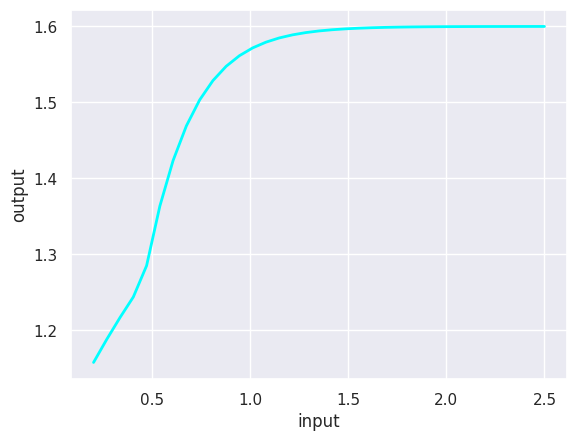

In [80]:
sns.set_theme(style="darkgrid")
sns.lineplot(
    x=true_inputs, y=true_outputs,
    color='cyan',
    linewidth=2
)
plt.xlabel("input")
plt.ylabel("output")

In [81]:
class PlainFirstNN(nn.Module):
    
    def __init__(self):
        super().__init__()
        
        self.w00 = nn.Parameter(torch.tensor(0.0), requires_grad=True)
        self.b00 = nn.Parameter(torch.tensor(-0.5), requires_grad=False)

        self.w01 = nn.Parameter(torch.tensor(0.6), requires_grad=False)
        self.b01 = nn.Parameter(torch.tensor(-1.5), requires_grad=False)

        self.w02 = nn.Parameter(torch.tensor(0.0), requires_grad=True)
        self.b02 = nn.Parameter(torch.tensor(0.65), requires_grad=False)

        self.w11 = nn.Parameter(torch.tensor(1.55), requires_grad=False)
        self.w12 = nn.Parameter(torch.tensor(-0.7), requires_grad=False)
        self.w13 = nn.Parameter(torch.tensor(1.22), requires_grad=False)

        self.w20 = nn.Parameter(torch.tensor(0.0), requires_grad=True)
        
    
    def forward(self, input):
        input_to_layer_1 = input * self.w00 + self.b00
        layer_01_output = F.relu(input_to_layer_1)
        layer_01_output = layer_01_output * self.w11
        
        input_to_layer_2 = input * self.w01 + self.b01
        layer_02_output = F.relu(input_to_layer_2)
        layer_02_output = layer_02_output * self.w12
        
        input_to_layer_3 = input * self.w02 + self.b02
        layer_03_output = F.relu(input_to_layer_3)
        layer_03_output = layer_03_output * self.w13
        
        output = layer_01_output + layer_02_output + layer_03_output
        
        output = F.tanh(output)
        output = output * self.w20
        
        return output
    
    

In [82]:
plain_first_model = PlainFirstNN()


In [83]:
pred_outputs = plain_first_model(true_inputs)
pred_outputs

tensor([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.], grad_fn=<MulBackward0>)

<Axes: xlabel='None', ylabel='None'>

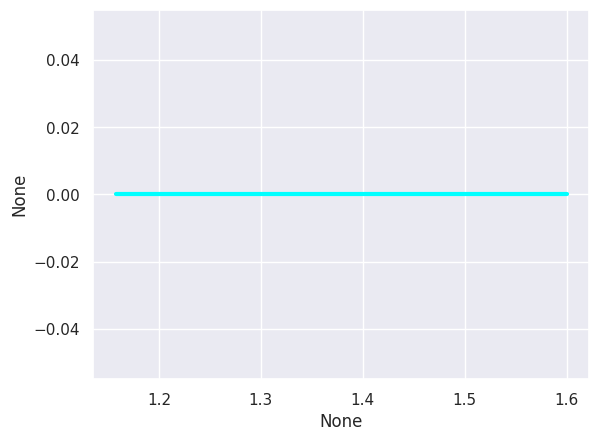

In [84]:
sns.set(style="darkgrid")
sns.lineplot(x=true_outputs, y=pred_outputs.detach(), color = 'cyan', linewidth=3)

In [85]:
optimizer=SGD(plain_first_model.parameters(), lr=0.01)
loss = nn.MSELoss()

In [86]:
for epoch in range(100):
    total_loss = 0
    for i in range(len(true_inputs)):
        input_i = true_inputs[i]
        true_output_i = true_outputs[i]
        pred_output_i = plain_first_model(input_i)
        
        loss_value = loss(pred_output_i, true_output_i)
        
        loss_value.backward()
        total_loss += loss_value
        
        print(f"epoch: {epoch} | total loss: {total_loss}")
        
        optimizer.step()
        optimizer.zero_grad()

epoch: 0 | total loss: 1.340124487876892
epoch: 0 | total loss: 2.7279999256134033
epoch: 0 | total loss: 4.1596879959106445
epoch: 0 | total loss: 5.631232261657715
epoch: 0 | total loss: 7.1779375076293945
epoch: 0 | total loss: 8.897286415100098
epoch: 0 | total loss: 10.746506690979004
epoch: 0 | total loss: 12.688117980957031
epoch: 0 | total loss: 14.691049575805664
epoch: 0 | total loss: 16.730487823486328
epoch: 0 | total loss: 18.78709602355957
epoch: 0 | total loss: 20.846044540405273
epoch: 0 | total loss: 22.89603614807129
epoch: 0 | total loss: 24.928466796875
epoch: 0 | total loss: 26.936731338500977
epoch: 0 | total loss: 28.91567611694336
epoch: 0 | total loss: 30.861188888549805
epoch: 0 | total loss: 32.7698974609375
epoch: 0 | total loss: 34.63895034790039
epoch: 0 | total loss: 36.46589279174805
epoch: 0 | total loss: 38.248558044433594
epoch: 0 | total loss: 39.98503875732422
epoch: 0 | total loss: 41.67366409301758
epoch: 0 | total loss: 43.31300735473633
epoch: 0

In [87]:
pred_outputs = plain_first_model(true_inputs)
pred_outputs

tensor([1.2185, 1.2584, 1.2948, 1.3282, 1.3585, 1.3862, 1.4112, 1.4339, 1.4545,
        1.4730, 1.4898, 1.5049, 1.5185, 1.5307, 1.5416, 1.5515, 1.5603, 1.5683,
        1.5754, 1.5817, 1.5874, 1.5925, 1.5971, 1.6012, 1.6048, 1.6081, 1.6110,
        1.6136, 1.6159, 1.6180, 1.6198, 1.6215, 1.6230, 1.6243, 1.6255],
       grad_fn=<MulBackward0>)

Text(0.5, 0, 'input')

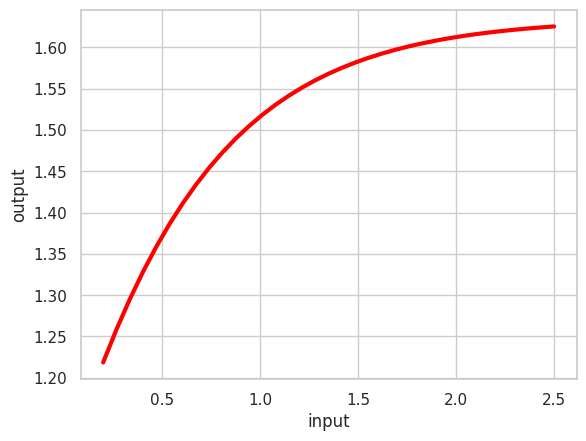

In [88]:
sns.set(style="whitegrid")

sns.lineplot(
    x=true_inputs,
    y=pred_outputs.detach(),
    color='red',
    linewidth=3
)

plt.ylabel('output')
plt.xlabel('input')

In [89]:
plain_first_model.w00

Parameter containing:
tensor(0., requires_grad=True)

In [90]:
plain_first_model.w20

Parameter containing:
tensor(1.6352, requires_grad=True)

In [91]:
tensor_2d = torch.zeros(2,4,3,3,2)
tensor_2d

tensor([[[[[0., 0.],
           [0., 0.],
           [0., 0.]],

          [[0., 0.],
           [0., 0.],
           [0., 0.]],

          [[0., 0.],
           [0., 0.],
           [0., 0.]]],


         [[[0., 0.],
           [0., 0.],
           [0., 0.]],

          [[0., 0.],
           [0., 0.],
           [0., 0.]],

          [[0., 0.],
           [0., 0.],
           [0., 0.]]],


         [[[0., 0.],
           [0., 0.],
           [0., 0.]],

          [[0., 0.],
           [0., 0.],
           [0., 0.]],

          [[0., 0.],
           [0., 0.],
           [0., 0.]]],


         [[[0., 0.],
           [0., 0.],
           [0., 0.]],

          [[0., 0.],
           [0., 0.],
           [0., 0.]],

          [[0., 0.],
           [0., 0.],
           [0., 0.]]]],



        [[[[0., 0.],
           [0., 0.],
           [0., 0.]],

          [[0., 0.],
           [0., 0.],
           [0., 0.]],

          [[0., 0.],
           [0., 0.],
           [0., 0.]]],


         [[[0

In [92]:
torch1 = torch.arange(10)
torch1

tensor([0, 1, 2, 3, 4, 5, 6, 7, 8, 9])

In [93]:
torch2 = torch1.reshape(5,2)
torch2

tensor([[0, 1],
        [2, 3],
        [4, 5],
        [6, 7],
        [8, 9]])

In [94]:
torch2[:1, 0]

tensor([0])

In [95]:
tensor1 = torch.tensor([0,1,2,3,4])
tensor2 = torch.tensor([5,6,7,8,9])

In [96]:
tensor1 + tensor2

tensor([ 5,  7,  9, 11, 13])

In [97]:
torch.add(tensor1, tensor2)

tensor([ 5,  7,  9, 11, 13])

In [98]:
import torch
import torch.nn as nn
import torch.nn.functional as F

In [99]:
class NeuralNetwork(nn.Module):
    
    def __init__(self, in_features = 4, h1=8, h2=9, out_features=3):
        super().__init__()
        
        self.fc1 = nn.Linear(in_features, h1)
        self.fc2 = nn.Linear(h1, h2)
        self.out = nn.Linear(h2, out_features)
        
    def forward(self, x):
        
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = self.out(x)
        
        return x
    
        
        
        

In [100]:
torch.manual_seed(42)

model = NeuralNetwork()

In [101]:
import pandas as pd
import matplotlib as plt
%matplotlib inline

In [102]:
url = 'https://gist.githubusercontent.com/curran/a08a1080b88344b0c8a7/raw/0e7a9b0a5d22642a06d3d5b9bcbad9890c8ee534/iris.csv'

df = pd.read_csv(url)

In [103]:
df

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,virginica
146,6.3,2.5,5.0,1.9,virginica
147,6.5,3.0,5.2,2.0,virginica
148,6.2,3.4,5.4,2.3,virginica


In [104]:
df['species'] = df['species'].replace('setosa', 0.0)
df['species'] = df['species'].replace('versicolor', 1.0)
df['species'] = df['species'].replace('virginica', 2.0)
df

/tmp/ipykernel_2244/386613633.py:3: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df['species'] = df['species'].replace('virginica', 2.0)


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,0.0
1,4.9,3.0,1.4,0.2,0.0
2,4.7,3.2,1.3,0.2,0.0
3,4.6,3.1,1.5,0.2,0.0
4,5.0,3.6,1.4,0.2,0.0
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,2.0
146,6.3,2.5,5.0,1.9,2.0
147,6.5,3.0,5.2,2.0,2.0
148,6.2,3.4,5.4,2.3,2.0


In [105]:
df["species"].value_counts()

,count
species,
0.0,50
1.0,50
2.0,50


In [106]:
df = df.rename(columns={'species' : 'category'})

In [107]:
df

,sepal_length,sepal_width,petal_length,petal_width,category
0,5.1,3.5,1.4,0.2,0.0
1,4.9,3.0,1.4,0.2,0.0
2,4.7,3.2,1.3,0.2,0.0
3,4.6,3.1,1.5,0.2,0.0
4,5.0,3.6,1.4,0.2,0.0
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,2.0
146,6.3,2.5,5.0,1.9,2.0
147,6.5,3.0,5.2,2.0,2.0
148,6.2,3.4,5.4,2.3,2.0


In [108]:
X = df.drop('category', axis = 1)
y = df['category']

In [109]:
X

,sepal_length,sepal_width,petal_length,petal_width
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2
...,...,...,...,...
145,6.7,3.0,5.2,2.3
146,6.3,2.5,5.0,1.9
147,6.5,3.0,5.2,2.0
148,6.2,3.4,5.4,2.3


In [110]:
y

,category
0,0.0
1,0.0
2,0.0
3,0.0
4,0.0
...,...
145,2.0
146,2.0
147,2.0
148,2.0


#### convert X table to a np array through X.values

In [111]:
X = X.values
y = y.values

In [112]:
type(X)

numpy.ndarray

In [113]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=.2, random_state=42)

##### Now we want to convert np arrays to tensors to work with torch

In [114]:
x_train = torch.FloatTensor(x_train)
x_test = torch.FloatTensor(x_test)

In [115]:
y_train = torch.LongTensor(y_train)
y_test = torch.LongTensor(y_test)

In [116]:
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

In [119]:
epochs = 100
losses = []

for epoch in range(epochs):
    y_pred = model.forward(x_train)
    
    loss = criterion(y_pred, y_train)
    losses.append(loss.detach().numpy())
    
    # print loss every 10 epochs:
    
    if epoch % 10 == 0:
        print(f"Epoch num: {epoch}, Loss equals: {loss}")
        
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    

Epoch num: 0, Loss equals: 0.0541173480451107
Epoch num: 10, Loss equals: 0.053725939244031906
Epoch num: 20, Loss equals: 0.05387359485030174
Epoch num: 30, Loss equals: 0.05341760441660881
Epoch num: 40, Loss equals: 0.05286799743771553
Epoch num: 50, Loss equals: 0.052476976066827774
Epoch num: 60, Loss equals: 0.05218958854675293
Epoch num: 70, Loss equals: 0.05193651095032692
Epoch num: 80, Loss equals: 0.051679424941539764
Epoch num: 90, Loss equals: 0.05143653601408005
